# Titanic Data Analysis


### 1. Import Library

In [794]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

### 2. Load dataset

In [795]:
# Project paths
PROJECT_DIR = Path.cwd().parent


RAW_DATA_PATH = PROJECT_DIR / "data" / "raw" / "train.csv"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
PROCESSED_DATA_PATH = PROJECT_DIR / "data" / "processed" / "train_clean.csv"
ENCODED_DATA_PATH = PROJECT_DIR / "data" / "encoded" / "train_encoded.csv"   

df = pd.read_csv(RAW_DATA_PATH)
df_original = df.copy()      # untouched backup, we only change df
df.head(10)
df.tail(10)
df.sample(10, random_state=1)

,Unnamed: 0,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Constant_Flag,Notes,Fare_Copy,Random_Token,Data_Source
267,267,656,0,2,"Hickman, Mr. Leonard Mark",male,24.0,45,0,S.O.C. 14879,73.5,NaN,NaN,TRAIN,NaN,73.5,931404,titanic_v2_export
291,291,133,0,3,"Robins, Mrs. Alexander A (Grace Charity Laury)",f,47.0,1,0,A/5.3337,14.5,NaN,S,TRAIN,NaN,14.5,929666,titanic_v2_export
480,480,431,1,1,"Bjornstrom-Steffansson, Mr. Mauritz Hakan",male,28.0,0,0,110564,26.55,C52,S,TRAIN,NaN,26.55,135252,titanic_v2_export
341,341,794,0,1,"Hoyt, Mr. William Fisher",M,NaN,0,0,PC 17600,30.6958,NaN,C,TRAIN,NaN,30.6958,747803,titanic_v2_export
320,320,473,1,2,"West, Mrs. Edwy Arthur (Ada Mary Worth)",female,33.0,1,2,C.A. 34651,27.75,NaN,s,TRAIN,NaN,27.75,771761,titanic_v2_export
35,35,659,0,2,"Eitemiller, Mr. George Floyd",male,23.0,0,0,29751,NaN,NaN,S,TRAIN,NaN,NaN,647866,titanic_v2_export
926,926,580,1,3,"Jussila, Mr. Eiriik",male,32.0,0,0,STON/O 2. 3101286,7.925,NaN,S,TRAIN,NaN,7.925,942647,titanic_v2_export
205,205,23,1,3,"McGowan, Miss. Anna ""Annie""",female,15.0,0,0,330923,8.0292,NaN,Q,TRAIN,NaN,8.0292,213097,titanic_v2_export
849,849,124,1,2,"Webber, Miss. Susan",NaN,32.5,0,0,27267,13.0,E101,s,TRAIN,NaN,13.0,939500,titanic_v2_export
754,754,77,0,3,"Staneff, Mr. Ivan",male,NaN,0,0,349208,NaN,NaN,S,TRAIN,NaN,NaN,569297,titanic_v2_export


### 3. Understanding the dataset

In [796]:
print(df.shape)
df.dtypes

(931, 18)


Unnamed: 0         int64
PassengerId        int64
Survived             str
Pclass               str
Name                 str
Sex                  str
Age                  str
SibSp                str
Parch              int64
Ticket               str
Fare                 str
Cabin                str
Embarked             str
Constant_Flag        str
Notes            float64
Fare_Copy            str
Random_Token       int64
Data_Source          str
dtype: object

In [797]:
# Age, Fare, Pclass, Survived, SibSp should be numbers. If they show as text, the types are wrong.
df.describe()
df.describe(include=["object", "string"])

,Survived,Pclass,Name,Sex,Age,SibSp,Ticket,Fare,Cabin,Embarked,Constant_Flag,Fare_Copy,Data_Source
count,916,911,931,903,743,931,931,888,211,908,931,888,931
unique,13,12,900,14,117,13,689,276,141,17,1,276,1
top,0,3,"Rush, Mr. Alfred George John",male,24.0,0,347082,8.05,none,S,TRAIN,8.05,titanic_v2_export
freq,543,480,2,531,29,624,8,44,5,605,931,44,931


In [798]:
df.nunique().sort_values()
for col in ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    print(col, df[col].value_counts(dropna=False).to_dict())
    
for col in ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    print(df[col].unique())


Survived {'0': 543, '1': 333, nan: 15, 'N': 7, '-1': 5, 'Yes': 5, 'no': 4, 'False': 4, 'yes': 3, 'No': 3, 'True': 3, 'Y': 2, '2': 2, '5': 2}
Pclass {'3': 480, '1': 206, '2': 184, nan: 20, '3rd': 17, '1st': 9, '4': 4, '33': 4, 'First': 2, '2nd': 2, '7': 1, 'Second': 1, 'Third': 1}
Sex {'male': 531, 'female': 278, nan: 28, 'male ': 17, 'Male': 13, 'M': 9, 'f': 9, 'F': 9, ' male': 8, 'm': 7, 'MALE': 6, 'female ': 5, 'Female': 4, 'FEMALE': 4, ' female': 3}
SibSp {'0': 624, '1': 213, '2': 27, '4': 20, '3': 17, '8': 8, '5': 4, 'zero': 4, '-1': 3, '45': 3, '0.0': 3, 'one': 3, '1.0': 2}
Parch {0: 709, 1: 122, 2: 85, 5: 5, 3: 5, 4: 4, 6: 1}
Embarked {'S': 605, 'C': 160, 'Q': 74, nan: 23, 's': 18, 'southampton': 12, ' S': 11, 'Southampton': 7, '9': 4, 'c': 4, 'C ': 3, 'CHERBOURG': 2, 'X': 2, 'QUEENSTOWN': 2, ' Q': 1, 'Cherbourg': 1, 'q': 1, 'Z': 1}
<StringArray>
[    '0',     '1',     nan,    '-1',   'Yes',     'N',   'yes',    'no',
     'Y', 'False',    'No',     '2',  'True',     '5']
Length:

In [799]:
missing = pd.DataFrame({"count": df.isnull().sum(),"percent": (df.isnull().mean() * 100).round(1)})
missing.sort_values("percent", ascending=False)

,count,percent
Notes,931,100.00
Cabin,720,77.30
Age,188,20.20
Fare_Copy,43,4.60
Fare,43,4.60
Sex,28,3.00
Embarked,23,2.50
Pclass,20,2.10
Survived,15,1.60
Unnamed: 0,0,0.00


In [800]:
print(df.duplicated().sum())

if not df["PassengerId"].is_unique:
    print("duplicates exist:", df["PassengerId"].duplicated().sum())   

0
duplicates exist: 40


In [801]:
# verifying are these same columens 
df.nunique()                          
df["Fare"].equals(df["Fare_Copy"])    

True


### 4. Data Cleaning

#### 4.1 Inspect the messy columns first

In [802]:
for col in ["Survived", "Pclass", "Sex", "SibSp", "Embarked"]:
    print(col, df[col].value_counts(dropna=False).to_dict())
    print()

Survived {'0': 543, '1': 333, nan: 15, 'N': 7, '-1': 5, 'Yes': 5, 'no': 4, 'False': 4, 'yes': 3, 'No': 3, 'True': 3, 'Y': 2, '2': 2, '5': 2}

Pclass {'3': 480, '1': 206, '2': 184, nan: 20, '3rd': 17, '1st': 9, '4': 4, '33': 4, 'First': 2, '2nd': 2, '7': 1, 'Second': 1, 'Third': 1}

Sex {'male': 531, 'female': 278, nan: 28, 'male ': 17, 'Male': 13, 'M': 9, 'f': 9, 'F': 9, ' male': 8, 'm': 7, 'MALE': 6, 'female ': 5, 'Female': 4, 'FEMALE': 4, ' female': 3}

SibSp {'0': 624, '1': 213, '2': 27, '4': 20, '3': 17, '8': 8, '5': 4, 'zero': 4, '-1': 3, '45': 3, '0.0': 3, 'one': 3, '1.0': 2}

Embarked {'S': 605, 'C': 160, 'Q': 74, nan: 23, 's': 18, 'southampton': 12, ' S': 11, 'Southampton': 7, '9': 4, 'c': 4, 'C ': 3, 'CHERBOURG': 2, 'X': 2, 'QUEENSTOWN': 2, ' Q': 1, 'Cherbourg': 1, 'q': 1, 'Z': 1}



#### 4.2 Drop junk columns

In [803]:
df = df.drop(columns=["Unnamed: 0", "Constant_Flag", "Notes", "Fare_Copy", "Random_Token", "Data_Source"])
df.shape

(931, 12)

#### 4.3 Remove extra spaces and convert disguised nulls to NaN

In [804]:
# strip spaces from every text column
text_columns = df.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    df[col] = df[col].str.strip()

# words that mean "missing" -> real NaN
df = df.replace(["?", "N/A", "NA", "n/a", "unknown", "null", "none", "None", "-", ""], np.nan)
df.isnull().sum()

PassengerId      0
Survived        15
Pclass          20
Name             0
Sex             28
Age            200
SibSp            0
Parch            0
Ticket           0
Fare            43
Cabin          734
Embarked        23
dtype: int64

#### 4.4 Standardize text (Sex, Embarked, Name, Ticket)

In [805]:
# Sex: take the first letter (m / f) and map it
df["Sex"] = df["Sex"].str.lower().str[0].map({"m": "male", "f": "female"})

# Embarked: first letter in capital (Southampton -> S)
df["Embarked"] = df["Embarked"].str.upper().str[0]

# Ticket: capital letters
df["Ticket"] = df["Ticket"].str.upper()

# Name: fix spacing, and fix names that are ALL CAPS or all lowercase
df["Name"] = df["Name"].str.replace(",", ", ").str.replace(".", ". ", regex=False)
df["Name"] = df["Name"].str.replace("  ", " ").str.strip()
for i in df.index:
    name = df.loc[i, "Name"]
    if pd.notnull(name) and (name.isupper() or name.islower()):
        df.loc[i, "Name"] = name.title()

print(df["Sex"].value_counts(dropna=False).to_dict())
print(df["Embarked"].value_counts(dropna=False).to_dict())

{'male': 591, 'female': 312, nan: 28}
{'S': 653, 'C': 170, 'Q': 78, nan: 23, '9': 4, 'X': 2, 'Z': 1}


#### 4.5 Fix data types
Rule: **map the words first, then `pd.to_numeric` last.** If you convert first, the words turn into NaN and are lost.

In [806]:
# Age: words and units -> number text -> number
age_words = {"eighteen": "18", "five": "5", "thirty": "30", "thirty-five": "35",
             "twenty-five": "25", "twenty-two": "22"}
df["Age"] = df["Age"].str.lower().replace(age_words)
df["Age"] = df["Age"].str.replace(" years", "").str.replace("yrs", "")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Fare: remove $ and use . as the decimal sign
df["Fare"] = df["Fare"].str.replace("$", "", regex=False).str.replace(",", ".")
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")

# Pclass: 1st / First -> 1 ...
pclass_map = {"1st": "1", "first": "1", "2nd": "2", "second": "2", "3rd": "3", "third": "3"}
df["Pclass"] = df["Pclass"].str.lower().replace(pclass_map)
df["Pclass"] = pd.to_numeric(df["Pclass"], errors="coerce")

# Survived: Yes / No / True / False -> 1 / 0
survived_map = {"yes": "1", "y": "1", "true": "1", "no": "0", "n": "0", "false": "0"}
df["Survived"] = df["Survived"].str.lower().replace(survived_map)
df["Survived"] = pd.to_numeric(df["Survived"], errors="coerce")

# SibSp: words -> numbers
sibsp_map = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "eight": "8"}
df["SibSp"] = df["SibSp"].str.lower().replace(sibsp_map)
df["SibSp"] = pd.to_numeric(df["SibSp"], errors="coerce")

df.dtypes

PassengerId      int64
Survived       float64
Pclass         float64
Name               str
Sex                str
Age            float64
SibSp          float64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

#### 4.6 Incorrect values -> NaN
Now the columns are numbers, so range rules work. We don't delete these rows, we only blank the bad value and fill it in Step 2.

In [807]:
df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan
df.loc[(df["Fare"] < 0) | (df["Fare"] > 600), "Fare"] = np.nan     
df.loc[~df["Pclass"].isin([1, 2, 3]), "Pclass"] = np.nan           
df.loc[~df["Survived"].isin([0, 1]), "Survived"] = np.nan
df.loc[(df["SibSp"] < 0) | (df["SibSp"] > 8), "SibSp"] = np.nan
df.loc[~df["Embarked"].isin(["S", "C", "Q"]), "Embarked"] = np.nan

#### 4.7 Verification

In [808]:
print(df["Pclass"].value_counts(dropna=False).to_dict())    # only 1, 2, 3 and NaN
print(df["Survived"].value_counts(dropna=False).to_dict())  # only 0, 1 and NaN
df.describe()

{3.0: 498, 1.0: 217, 2.0: 187, nan: 29}
{0.0: 561, 1.0: 346, nan: 24}


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,931.00,907.00,902.00,719.00,925.00,931.00,880.00
mean,446.97,0.38,2.31,29.52,0.53,0.38,31.81
std,257.21,0.49,0.83,14.48,1.12,0.80,49.44
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.00,0.00,2.00,20.00,0.00,0.00,7.90
50%,449.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,670.50,1.00,3.00,38.00,1.00,0.00,30.70
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33



### 5. Handling Missing Values

#### 5.1 Measure the problem

In [809]:
missing = pd.DataFrame({"count": df.isnull().sum(),"percent": (df.isnull().mean() * 100).round(1)})
missing.sort_values("percent", ascending=False)

,count,percent
Cabin,734,78.80
Age,212,22.80
Fare,51,5.50
Embarked,30,3.20
Pclass,29,3.10
Sex,28,3.00
Survived,24,2.60
SibSp,6,0.60
Name,0,0.00
PassengerId,0,0.00


#### 5.2 Survived (target): drop the rows, never fill it

In [810]:
df = df.dropna(subset=["Survived"])
df = df.reset_index(drop=True)       # reset the index because we use loops with df.loc[i] below
df["Survived"] = df["Survived"].astype(int)
df.shape

(907, 12)

#### 5.3 Sex: recover it from the title in Name (Mr, Mrs, Miss ...)

In [811]:
# Name looks like: "Braund, Mr. Owen Harris" -> take the text between "," and "."
df["Title"] = df["Name"].str.split(",").str[1].str.split(".").str[0].str.strip()
df["Title"].value_counts()

Title
Mr              528
Miss            183
Mrs             125
Master           42
Dr                7
Rev               6
Major             3
Col               2
Mlle              2
Sir               2
Don               1
Lady              1
Mme               1
Jonkheer          1
Ms                1
the Countess      1
Capt              1
Name: count, dtype: int64

In [812]:
male_titles = ["Mr", "Master", "Rev", "Don", "Major", "Col", "Capt", "Sir", "Jonkheer"]
female_titles = ["Mrs", "Miss", "Ms", "Mme", "Mlle", "Lady", "the Countess", "Dona"]

for i in df.index:
    if pd.isnull(df.loc[i, "Sex"]):
        title = df.loc[i, "Title"]
        if title in male_titles:
            df.loc[i, "Sex"] = "male"
        elif title in female_titles:
            df.loc[i, "Sex"] = "female"

# still missing (e.g. title "Dr")? use the most common value
df["Sex"] = df["Sex"].fillna(df["Sex"].mode()[0])
df["Sex"].isnull().sum()

np.int64(0)

#### 5.4 Embarked and SibSp: fill with the most common value (mode)

In [813]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["SibSp"] = df["SibSp"].fillna(df["SibSp"].mode()[0])
df["SibSp"] = df["SibSp"].astype(int)
print(df["Embarked"].isnull().sum(), df["SibSp"].isnull().sum())

0 0


#### 5.5 Fare and Pclass: use the class average and the "closest" idea
1. Find the average Fare of class 1, 2 and 3.
2. Pclass missing but Fare known -> pick the class whose average is **closest** to the fare.
3. Pclass still missing (Fare also missing) -> most common class.
4. Fare missing -> average Fare of the passenger's class.

In [814]:
# Step 1: average fare of each class
class_avg = df.groupby("Pclass")["Fare"].mean()
class_avg

Pclass
1.00   79.65
2.00   20.04
3.00   13.68
Name: Fare, dtype: float64

In [815]:
# If Pclass is missing AND Fare is given -> fill with closest class_avg
mask = df["Pclass"].isnull() & df["Fare"].notnull()
df.loc[mask, "Pclass"] = df.loc[mask, "Fare"].apply(lambda f: (class_avg - f).abs().idxmin())

# If both were missing (remaining NaNs in Pclass) -> fill with mode
df["Pclass"] = df["Pclass"].fillna(df["Pclass"].mode()[0]).astype(int)

# If Pclass is given (which is now every row!) -> fill missing Fare with class_avg
df["Fare"] = df["Fare"].fillna(df["Pclass"].map(class_avg))

print(df["Pclass"].isnull().sum(),"\t", df["Fare"].isnull().sum())

0 	 0


#### 5.6 Age: average age of the Sex group

In [816]:
age_avg = df.groupby(["Sex"])["Age"].mean().round()
age_avg

Sex
female   27.00
male     31.00
Name: Age, dtype: float64

In [817]:
for i in df.index:
    if pd.isnull(df.loc[i, "Age"]):
        group = ( df.loc[i, "Sex"])
        df.loc[i, "Age"] = age_avg[group]

df["Age"].isnull().sum()

np.int64(0)

#### 5.7 Verification 
Not filling cabin because it is missing over 77% of the data that can't be filled but used as feature(variable)

In [818]:
print(df.shape)
print(df.isnull().sum())   
df.dtypes
df.describe()

(907, 13)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          713
Embarked         0
Title            0
dtype: int64


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,907.00,907.00,907.00,907.00,907.00,907.00,907.00
mean,450.29,0.38,2.30,29.64,0.53,0.38,31.88
std,255.72,0.49,0.84,12.82,1.13,0.80,48.49
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,229.50,0.00,2.00,22.00,0.00,0.00,7.92
50%,454.00,0.00,3.00,30.00,0.00,0.00,14.45
75%,672.50,1.00,3.00,35.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


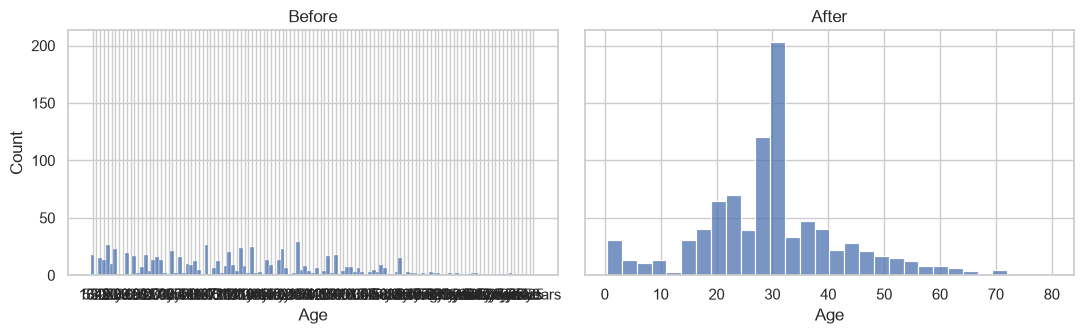

In [819]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
sns.histplot(df_original["Age"].dropna(), bins=30, ax=ax1)
sns.histplot(df["Age"], bins=30, ax=ax2)
ax1.set_title("Before")
ax2.set_title("After")
plt.tight_layout()   

### 6. Handling Duplicate Records


In [820]:
print(df.duplicated().sum())

if not df["PassengerId"].is_unique:
    print("duplicates exist:", df["PassengerId"].duplicated().sum())   

39
duplicates exist: 39


In [821]:
df[df.duplicated(keep=False)].sort_values("PassengerId" , ascending= False).head(2) # keep fasle give all copy not only 1

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
180,871,0,3,"Balkic, Mr. Cerin",male,26.00,0,0,349248,7.90,NaN,S,Mr
196,871,0,3,"Balkic, Mr. Cerin",male,26.00,0,0,349248,7.90,NaN,S,Mr



When deduplicating records by `PassengerId`, duplicate entries can sometimes contain different levels of completeness (for example, one row missing `Age` and `Cabin` while another row has those fields populated). 

Instead of blindly keeping the first row encountered, this pipeline prioritizes **data completeness**:

1. **Count missing values:** Calculates the number of null (`NaN`) fields per row.
2. **Prioritize complete rows:** Sorts the dataset so rows with the fewest missing values appear first.
3. **Deduplicate:** Drops duplicate `PassengerId` entries, retaining the most complete record.
4. **Clean up:** Removes the temporary null-count helper column and restores sorting by `PassengerId`.

In [822]:
# before = len(df) 
# df = df.drop_duplicates()                                     # removes exact duplicates
# df = df.drop_duplicates(subset="PassengerId", keep="first")   #  removes same passenger, different details
# print("Removed:", before - len(df))

In [823]:
df = (df.assign(_nulls=df.isnull().sum(axis=1))  # create a temporary column counting the null values 
        .sort_values("_nulls")                   # sort data set bsed on null values 
        .drop_duplicates(subset="PassengerId", keep="first") # remove others except first
        .drop(columns="_nulls")                  # remove _null column
        .sort_values("PassengerId"))             # sort dataset on passenger id

#### 6.2 Verification

In [824]:
assert df.duplicated().sum() == 0 , "Duplicates still exists"
assert df["PassengerId"].is_unique , "Duplicates still exists"
df.shape

(868, 13)

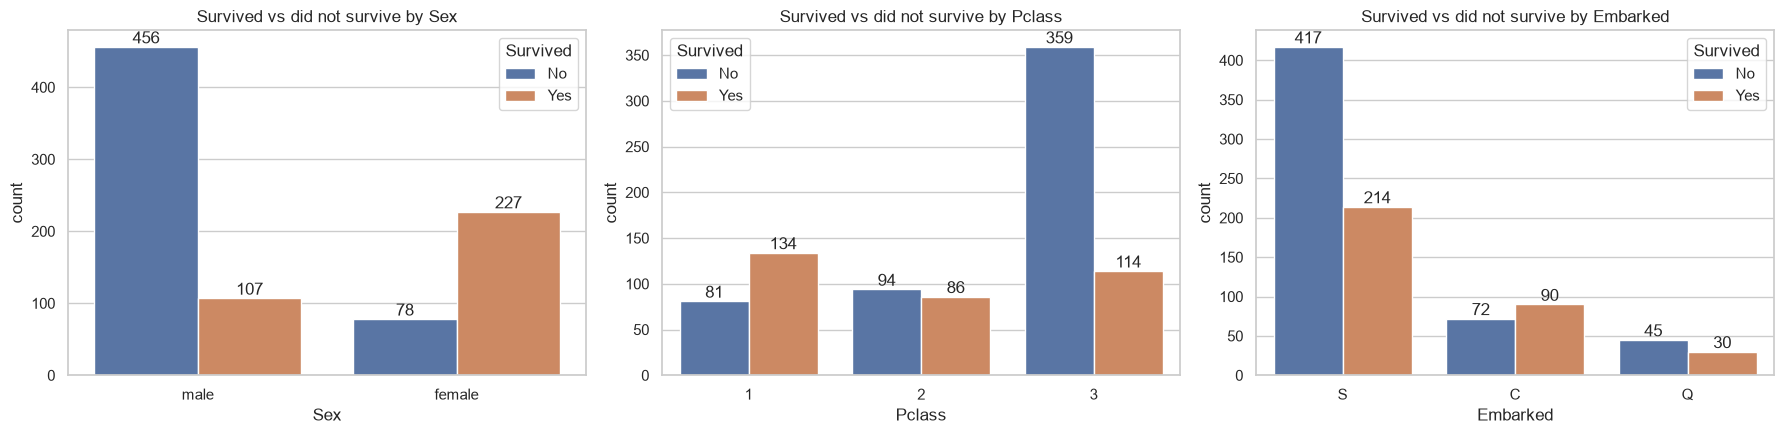

In [825]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for ax, c in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.countplot(x=c, hue="Survived", data=df, ax=ax)
    ax.set_title(f"Survived vs did not survive by {c}")
    ax.legend(title="Survived", labels=["No", "Yes"])
    for container in ax.containers:
        ax.bar_label(container)          # puts the count on each bar

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "survival_counts.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Adding features

In [826]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"].value_counts()
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df["Title"] = df["Title"].replace(title_map)
common = ["Mr", "Mrs", "Miss", "Master"]
df["Title"] = df["Title"].where(df["Title"].isin(common), "Rare")

In [827]:
df.groupby("Title")["Survived"].agg(["mean", "count"])

,mean,count
Title,,
Master,0.56,39
Miss,0.70,179
Mr,0.16,504
Mrs,0.80,123
Rare,0.35,23


#### 7.1 Family features

In [828]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)


#### 7.2 Cabin Feature

In [829]:
df["HasCabin"] = df["Cabin"].notna().astype("int")
df["Deck"] = df["Cabin"].str[0]
df["Deck"] = df["Deck"].fillna("Unknown")
# df = df.drop("Cabin", axis=1)



In [830]:
df["Deck"].head()

510    Unknown
707          C
300    Unknown
357    Unknown
365    Unknown
Name: Deck, dtype: str

#### 7.3 Binned numeric features

In [831]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
df["FareBand"] = pd.qcut(df["Fare"], q=4, labels=["Low", "Mid", "High", "Very High"],duplicates="drop") # use Interquartile Range

#### 7.4 Ticket-based features


In [832]:
df["TicketGroupSize"] = df.groupby("Ticket")["PassengerId"].transform("count")
df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]

#### 7.5 Testing new Features

        mean  count
Title              
Master  0.56     39
Miss    0.70    179
Mr      0.16    504
Mrs     0.80    123
Rare    0.35     23 

          mean  count
HasCabin             
0         0.31    682
1         0.67    186 

         mean  count
Deck                
A        0.43     14
B        0.78     45
C        0.57     49
D        0.75     32
E        0.77     30
F        0.64     11
G        0.50      4
T        0.00      1
Unknown  0.31    682 

             mean  count
AgeGroup                
Child        0.58     66
Teen         0.45     66
Young Adult  0.36    531
Adult        0.39    185
Senior       0.20     20 

           mean  count
FareBand              
Low        0.21    227
Mid        0.29    209
High       0.46    217
Very High  0.59    215 



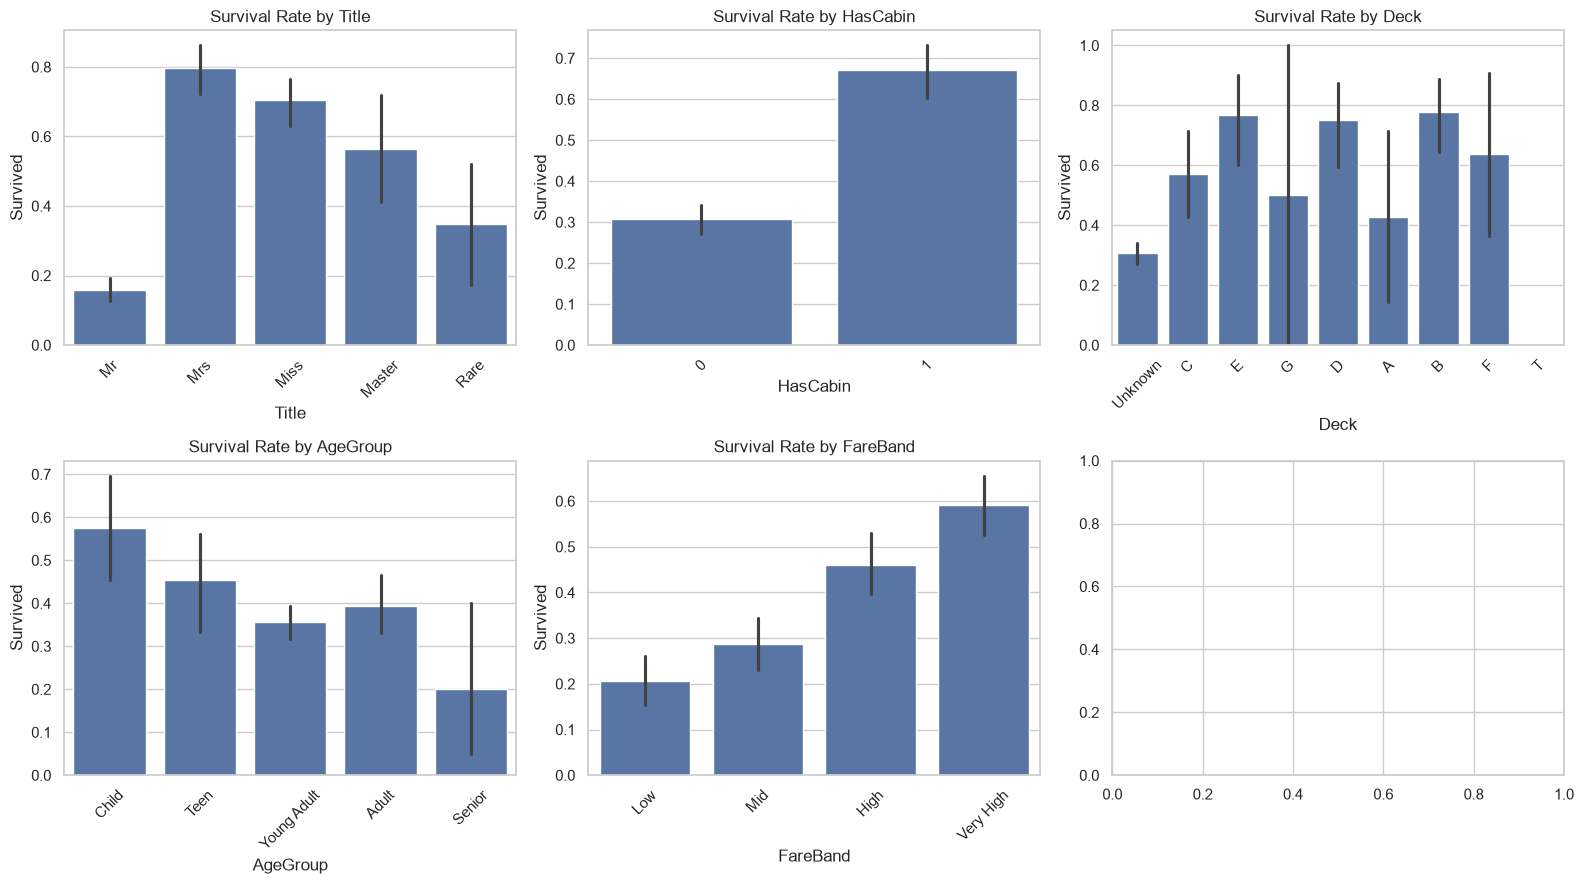

In [833]:

new_feats = ["Title", "HasCabin", "Deck", "AgeGroup", "FareBand"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, f in enumerate(new_feats):
    print(df.groupby(f)["Survived"].agg(["mean", "count"]), "\n")
    sns.barplot(x=f, y="Survived", data=df, ax=axes[i])
    axes[i].set_title(f"Survival Rate by {f}")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "feature_survival.png", dpi=150, bbox_inches="tight")
plt.show()


### 8. Data Transformation

#### 8.1 Checking for skewness

In [834]:
num_cols = ["Age", "Fare", "FarePerPerson", "SibSp", "Parch", "FamilySize"]
skew = df[num_cols].skew().sort_values(key=abs, ascending=False)
skew

FarePerPerson   8.25
Fare            4.95
SibSp           3.72
Parch           2.78
FamilySize      2.74
Age             0.42
dtype: float64

#### 8.2 Binning
Method one using binning to remove skewness applicable to FamilySize

In [835]:
df["FamilyGroup"] = pd.cut(df["FamilySize"], bins=[0, 1, 4, 20],labels=["Alone", "Small", "Large"])
df["FamilyGroup"].head()

510    Small
707    Small
300    Alone
357    Small
365    Alone
Name: FamilyGroup, dtype: category
Categories (3, str): ['Alone' < 'Small' < 'Large']

#### 8.3 Power Transform
Using log method to reduce high right skewness using **log1p** because it can handle 0.

In [836]:
skewed_cols = ["Fare" , "FarePerPerson"]
for col in skewed_cols:
    df[f"{col}_log"] = np.log1p(df[col])

print(df[[f"{col}_log" for col in skewed_cols]].skew())


Fare_log            0.39
FarePerPerson_log   0.48
dtype: float64


**SibSp Parch** is not that high so we can use from *sklearn.preprocessing import PowerTransformer*

In [837]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method="yeo-johnson")
df[["SibSp_yj", "Parch_yj"]] = pt.fit_transform(df[["SibSp", "Parch"]])

#### 8.4 Verification

In [838]:
skewed_cols = ["Fare_log","FarePerPerson_log","SibSp_yj","Parch_yj"]
print(df[[f"{col}" for col in skewed_cols]].skew())

Fare_log            0.39
FarePerPerson_log   0.48
SibSp_yj            0.81
Parch_yj            1.24
dtype: float64


### 9. Data Encoding

In [839]:
df_enc = df.copy()

#### 9.1 Binary encoding

In [840]:
df_enc["Sex"] = df_enc["Sex"].map({"male": 0, "female": 1})
df_enc["Sex"].head()

510    0
707    1
300    1
357    1
365    0
Name: Sex, dtype: int64

#### 9.2 Ordinal Encoding

In [841]:
age_order    = ["Child", "Teen", "Young Adult", "Adult", "Senior"]
fare_order   = ["Low", "Mid", "High", "Very High"]
family_order = ["Alone", "Small", "Large"]

df_enc["AgeGroup"]    = df_enc["AgeGroup"].astype(str).map({v: i for i, v in enumerate(age_order)})
df_enc["FareBand"]    = df_enc["FareBand"].astype(str).map({v: i for i, v in enumerate(fare_order)})
df_enc["FamilyGroup"] = df_enc["FamilyGroup"].astype(str).map({v: i for i, v in enumerate(family_order)})

group = ["AgeGroup", "FareBand", "FamilyGroup"]
print(df_enc[group].head())


     AgeGroup  FareBand  FamilyGroup
510         2         0            1
707         3         3            1
300         2         0            0
357         2         3            1
365         2         1            0


**SkLearn version** used in actuall pipelines

In [842]:
from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder(categories=[age_order])
df_enc["AgeGroup"] = enc.fit_transform(df[["AgeGroup"]])

#### 9.3 One hot encoding 
converts each unique text category into its own separate binary column of 1s and 0s

In [843]:
df["Deck"].value_counts()


Deck
Unknown    682
C           49
B           45
D           32
E           30
A           14
F           11
G            4
T            1
Name: count, dtype: int64

In [844]:
df_enc["Deck"] = df_enc["Deck"].replace({"G" : "Other" , "T" : " Other" , "Unknown" : "None"}) 


In [845]:
df_enc = pd.get_dummies(df_enc, columns=["Embarked", "Title", "Deck"],
                        drop_first=True, dtype=int)
df_enc.filter(like="Embarked_").head(20)

,Embarked_Q,Embarked_S
510,0,1
707,0,0
300,0,1
357,0,1
365,0,1
757,1,0
881,0,1
458,0,1
691,0,1
227,0,0


In [846]:
df_enc.filter(like="Title_").head()

,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
510,0,1,0,0
707,0,0,1,0
300,1,0,0,0
357,0,0,1,0
365,0,1,0,0


In [847]:
df_enc.filter(like="Deck_").head()

,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_None,Deck_Other
510,0,0,0,0,0,0,1,0
707,0,0,1,0,0,0,0,0
300,0,0,0,0,0,0,1,0
357,0,0,0,0,0,0,1,0
365,0,0,0,0,0,0,1,0


#### 9.4 Droping not encoded once

In [848]:
df_enc = df_enc.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")

#### 9.5 Verification and Saving Encoded Data

In [849]:
df_enc.dtypes          # no object / category columns left
df_enc.isnull().sum()  # all zeros (or only columns you deliberately left)
df_enc.shape
df_enc.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,AgeGroup,FareBand,TicketGroupSize,FarePerPerson,FamilyGroup,Fare_log,FarePerPerson_log,SibSp_yj,Parch_yj,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_None,Deck_Other
510,0,3,0,22.00,1,0,7.25,2,0,0,2.00,0,1,7.25,1,2.11,2.11,1.38,-0.56,0,1,0,1,0,0,0,0,0,0,0,0,1,0
707,1,1,1,38.00,1,0,71.28,2,0,1,3.00,3,1,71.28,1,4.28,4.28,1.38,-0.56,0,0,0,0,1,0,0,0,1,0,0,0,0,0
300,1,3,1,26.00,0,0,7.92,1,1,0,2.00,0,1,7.92,0,2.19,2.19,-0.68,-0.56,0,1,1,0,0,0,0,0,0,0,0,0,1,0
357,1,1,1,35.00,1,0,53.10,2,0,0,2.00,3,2,26.55,1,3.99,3.32,1.38,-0.56,0,1,0,0,1,0,0,0,0,0,0,0,1,0
365,0,3,0,35.00,0,0,8.05,1,1,0,2.00,1,1,8.05,0,2.20,2.20,-0.68,-0.56,0,1,0,1,0,0,0,0,0,0,0,0,1,0


In [850]:

df_enc.to_csv(ENCODED_DATA_PATH , index=False)
print("Saved:" , ENCODED_DATA_PATH , df_enc.shape )

Saved: d:\Projects\Titanic\data\encoded\train_encoded.csv (868, 33)


### 10. Save the cleaned data

In [851]:
df.to_csv(PROCESSED_DATA_PATH, index=False)
print("saved:", PROCESSED_DATA_PATH, df.shape)

saved: d:\Projects\Titanic\data\processed\train_clean.csv (868, 26)
